# Level 3: NLP Text Classification

1. Introduction

Natural Language Processing (NLP) is a field of artificial intelligence that enables computers to process and analyse human language.

Text classification is an NLP task in which text is assigned to a predefined category. In this project, we will build a model to classify SMS messages as either ham (legitimate messages) or spam (unwanted messages).

The project will cover data inspection, text preprocessing, text vectorisation using TF-IDF, model training, and evaluation using precision, recall, and F1-score.


### 2. Loading and Inspecting the Dataset

The SMS Spam Collection dataset contains text messages labelled as either ham or spam. Before preprocessing, we will load the original file and inspect its structure, dimensions, column names, data types, and sample records.

This initial inspection helps us confirm that the data has been loaded correctly and identify any issues that need attention before modelling.

Dataset source: SMS Spam Collection v.1, collected by Tiago A. Almeida and José María Gómez Hidalgo (http://www.dt.fee.unicamp.br/~tiago/smsspamcollection/). Reference: Almeida, T.A., Gómez Hidalgo, J.M., Yamakami, A. (2011). Contributions to the study of SMS Spam Filtering: New Collection and Results. Proceedings of the 2011 ACM Symposium on Document Engineering (DocEng'11), Mountain View, CA, USA.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the dataset in the current project folder
data_path = Path("SMSSpamCollection")

# Load the tab-separated file, which has no header row
df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

# Inspect the first five messages
display(df.head())

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Dataset Structure and Data Quality

After loading the dataset, we will inspect its dimensions, column data types, missing values, duplicate records, and class distribution. This helps us understand the amount and quality of data available before preprocessing and model training.

In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Count messages in each category
print("\nLabel distribution:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


## 4. Investigating Duplicate Messages

The initial inspection identified 403 duplicate rows. Before removing them, we will examine examples to understand whether the same message and label occur repeatedly.

Duplicate records can cause repeated examples to receive extra influence during model training. However, we should inspect the data before deciding how to handle them.

In [3]:

# Display examples of duplicate rows
duplicates = df[df.duplicated(keep=False)]

display(duplicates.sort_values(
    by=["label", "message"]
).head(50))

,label,message
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1470,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...
1779,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...
2982,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...
4556,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...
2370,ham,A Boy loved a gal. He propsd bt she didnt mind...
5104,ham,A Boy loved a gal. He propsd bt she didnt mind...
3749,ham,"A bit of Ur smile is my hppnss, a drop of Ur t..."


## 5. Removing Exact Duplicate Records

The inspection revealed repeated rows containing the same message and label. We will remove exact duplicate records while keeping the first occurrence of each unique label-message pair.

This reduces repeated examples without removing messages that differ in wording or label.

In [4]:
# Record the number of rows before removing duplicates
rows_before = len(df)

# Remove exact duplicate rows, keeping the first occurrence
df = df.drop_duplicates().reset_index(drop=True)

# Check the number of rows after removal
print("Rows before:", rows_before)
print("Rows after:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

Rows before: 5572
Rows after: 5169
Duplicates remaining: 0


## 6. Checking the Label Distribution After duplication

After removing exact duplicate records, we will examine the number and percentage of messages in each category. This helps us understand whether the dataset remains imbalanced and informs our choice of evaluation metrics for the classification models.

We will use the results to assess the representation of legitimate messages (ham) and spam messages (spam) before proceeding with text preprocessing.

In [5]:
# Count the messages in each category after deduplication
print(df["label"].value_counts())

# Show the percentage of each category
print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

label
ham     4516
spam     653
Name: count, dtype: int64

Label percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


## 7. Checking for Conflicting Labels

Removing exact duplicate rows does not guarantee that every message has a consistent label. The same message text could appear more than once with different labels, such as ham in one row and spam in another.

We will identify messages associated with more than one label. This helps us investigate possible labelling inconsistencies before training our classification models.

In [6]:
# Count the distinct labels associated with each message
labels_per_message = df.groupby("message")["label"].nunique()

# Identify messages associated with more than one label
conflicting_messages = labels_per_message[labels_per_message > 1]

print("Messages with conflicting labels:", len(conflicting_messages))

# Display examples if any exist
if len(conflicting_messages) > 0:
    display(
        df[df["message"].isin(conflicting_messages.index)]
        .sort_values("message")
        .head(10)
    )

Messages with conflicting labels: 0


## 8. Exploring Message Text

SMS messages often contain informal language, abbreviations, unusual capitalisation, punctuation, and other text patterns. Before preprocessing, we will examine message lengths and inspect examples from both categories.

This helps us understand the characteristics of the text and make informed decisions about cleaning it without unnecessarily removing useful information.

In [7]:
# Calculate the number of characters in each message
df["message_length"] = df["message"].str.len()

# Display basic statistics about message length
print("Message length statistics:")
print(df["message_length"].describe())

# Display three ham messages
print("\nExamples of ham messages:")
display(df.loc[df["label"] == "ham", "message"].head(3))

# Display three spam messages
print("\nExamples of spam messages:")
display(df.loc[df["label"] == "spam", "message"].head(3))

Message length statistics:
count    5169.000000
mean       79.344554
std        58.437457
min         2.000000
25%        36.000000
50%        61.000000
75%       119.000000
max       910.000000
Name: message_length, dtype: float64

Examples of ham messages:


0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
3    U dun say so early hor... U c already then say...
Name: message, dtype: str


Examples of spam messages:


2    Free entry in 2 a wkly comp to win FA Cup fina...
5    FreeMsg Hey there darling it's been 3 week's n...
8    WINNER!! As a valued network customer you have...
Name: message, dtype: str

## 9. Comparing Message Lengths by Category

Legitimate and spam messages may differ in length. We will compare their message-length distributions using summary statistics and a boxplot.

This exploration may reveal useful patterns in the dataset, but message length alone cannot determine whether a message is spam. We will use the findings to understand the data rather than assume a relationship before examining the results.

        count    mean    std   min    25%    50%    75%    max
label                                                         
ham    4516.0   70.91  56.72   2.0   34.0   53.0   91.0  910.0
spam    653.0  137.70  29.82  13.0  132.0  148.0  157.0  223.0


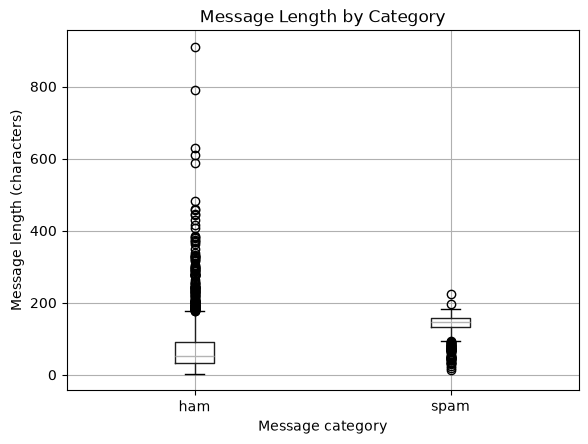

In [8]:
import matplotlib.pyplot as plt

# Compare message lengths by label
print(df.groupby("label")["message_length"].describe().round(2))

# Visualise the distributions
df.boxplot(column="message_length", by="label")
plt.title("Message Length by Category")
plt.suptitle("")
plt.xlabel("Message category")
plt.ylabel("Message length (characters)")
plt.show()

## 9.1 Interpretation of Message Length by Category

The boxplot and summary statistics show that spam messages are generally longer than ham messages in this dataset. The median spam message length is 148 characters, compared with 53 characters for ham. The mean lengths are approximately 137.70 and 70.91 characters, respectively.

The ham category also contains unusually long messages, with a maximum length of 910 characters, compared with 223 characters for spam. These extreme values appear as potential outliers in the boxplot and should not automatically be treated as errors.

Overall, message length may help describe differences between the two categories, but it cannot reliably determine whether a message is spam. We will retain the original message text and use further text analysis to build and evaluate our classification models.

## 10. Text Preprocessing

Text preprocessing involves preparing raw text for analysis and machine learning. SMS messages often contain inconsistent capitalisation, punctuation, abbreviations, numbers, and informal expressions.

In this project, we will examine which transformations are useful for spam classification. We will avoid removing information blindly because numbers, punctuation, capitalisation, and particular words may contain clues that help distinguish spam from legitimate messages.

The original message text will be preserved so that we can compare it with the processed text and assess whether our transformations are appropriate.

## 11. Lowercasing Text

Lowercasing converts uppercase letters to lowercase. For example, WINNER becomes winner.

This helps ensure that words differing only in capitalisation are treated consistently. Without lowercasing, a text vectoriser may treat WINNER and winner as separate features.

We will store the lowercase text in a new column called processed_message while preserving the original message column. This allows us to compare the original and transformed text and avoid losing the source data.

In [9]:
# Create a separate column containing lowercase messages
df["processed_message"] = df["message"].str.lower()

# Compare original and lowercase messages
display(df[["message", "processed_message"]].head(5))


,message,processed_message
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."


## 12. Splitting the Dataset

We will divide the dataset into training and testing sets using an 80:20 split. The training set will be used to develop the text classification models, while the test set will be reserved for evaluating their performance on unseen messages.

Stratification will preserve approximately the same proportions of ham and spam messages in both sets. We will retain the original messages so that we can compare preprocessing approaches without losing information about the original capitalisation.

The TF-IDF vectorizer will be fitted on training messages only and then applied to the test messages, preventing information from the test set from influencing the learned vocabulary and word weights.

In [10]:
from sklearn.model_selection import train_test_split

# Separate original messages and their labels
X = df["message"]
y = df["label"]

# Create stratified training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the split sizes and label proportions
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining label proportions (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting label proportions (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training rows: 4135
Testing rows: 1034

Training label proportions (%):
label
ham     87.38
spam    12.62
Name: proportion, dtype: float64

Testing label proportions (%):
label
ham     87.33
spam    12.67
Name: proportion, dtype: float64


## 13. Creating a Text-Cleaning Function

Text cleaning prepares messages for machine learning by applying consistent transformations. We will define a reusable function so the same rules can be applied to training and testing messages.

The function will convert text to lowercase and remove unnecessary leading, trailing, or repeated whitespace. We will preserve the original message for comparison and error analysis.

We will evaluate more aggressive preprocessing, such as stop-word removal and lemmatization, separately because removing words can sometimes discard useful information.

In [11]:
import re

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Replace repeated whitespace with a single space
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Test the function on three messages
sample_messages = X_train.head(3)

for message in sample_messages:
    print("Original:", message)
    print("Cleaned: ", clean_text(message))
    print("-" * 60)

Original: Ta-Daaaaa! I am home babe, are you still up ?
Cleaned:  ta-daaaaa! i am home babe, are you still up ?
------------------------------------------------------------
Original: Yup having my lunch buffet now.. U eat already?
Cleaned:  yup having my lunch buffet now.. u eat already?
------------------------------------------------------------
Original: Ok anyway no need to change with what you said
Cleaned:  ok anyway no need to change with what you said
------------------------------------------------------------


## 14. Tokenization

Tokenization is the process of splitting text into smaller units called tokens. In word-level tokenization, these tokens are usually individual words.

For example, the message Free entry to win a prize! can be split into tokens such as Free, entry, to, win, a, prize.

Tokenization helps us examine the words contained in messages and prepares text for further processing and numerical representation. However, we must choose a suitable tokenizer because punctuation, numbers and symbols may provide useful clues for spam classification.

We will first test tokenization on a sample message before deciding how to apply it to the dataset.

In [12]:
# Import NLTK to access natural language processing tools
import nltk

# Download punkt_tab, the tokenizer data required by NLTK to split text into tokens
nltk.download("punkt_tab")


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [13]:
# Import the word tokenizer from NLTK
from nltk.tokenize import word_tokenize

# Create a sample message for testing
sample_message = "WINNER!! Claim your FREE prize now!"

# Split the message into tokens
tokens = word_tokenize(sample_message)

# Display the original message and its tokens
print("Original message:", sample_message)
print("Tokens:", tokens)

Original message: WINNER!! Claim your FREE prize now!
Tokens: ['WINNER', '!', '!', 'Claim', 'your', 'FREE', 'prize', 'now', '!']


## 15. Stop-Word Removal

Stop words are common words that appear frequently in language, such as the, is, and, and to. In some NLP tasks, removing these words can reduce the number of words a model processes.

However, stop-word removal is not always beneficial. In spam classification, words such as free, claim, and win may be useful indicators of promotional messages. Words such as not can also change meaning, so removing them indiscriminately may discard useful information.

We will first test stop-word removal on a sample message to understand which words are removed. We will not remove stop words from the entire dataset until we have considered whether doing so is appropriate for our classification task.

In [14]:
# Download the English stop-word list to identify common words for possible removal during text preprocessing
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [15]:
from nltk.corpus import stopwords

# Load NLTK's English stop-word list
stop_words = set(stopwords.words("english"))

# Use a sample message to demonstrate stop-word removal
sample_message = "You are not eligible to win a free prize!"

# Split the sample into tokens
tokens = word_tokenize(sample_message)

# Remove tokens that appear in the stop-word list
filtered_tokens = [
    word for word in tokens
    if word.lower() not in stop_words
]

print("Original tokens:", tokens)
print("Tokens after stop-word removal:", filtered_tokens)

Original tokens: ['You', 'are', 'not', 'eligible', 'to', 'win', 'a', 'free', 'prize', '!']
Tokens after stop-word removal: ['eligible', 'win', 'free', 'prize', '!']


Stop-word removal involves removing common words such as `the`, `is`, and `are` that may contribute little to some text-analysis tasks.

We used NLTK's English stop-word list to demonstrate this process. However, removing words like `not` can change a message's meaning. Therefore, we will carefully consider whether stop-word removal is appropriate for our spam-classification model.

## 16. Understanding Lemmatization

Lemmatization reduces a word to its base or dictionary form, called its lemma. For example, running can become run, and cars can become car.

Unlike simple lowercase conversion, lemmatization changes word forms. Unlike stemming, it attempts to produce a valid dictionary word by considering linguistic information.

Why is it useful?

Words with different forms can express the same underlying concept. Reducing some of these differences may help a text-classification model recognise related words more consistently.

Important consideration: Lemmatization is not guaranteed to improve spam classification. We will test it on examples first and decide whether it is appropriate before applying it to the dataset.

In [16]:
# Download WordNet, the language resource required by WordNetLemmatizer
nltk.download("wordnet")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [17]:
# Check whether NLTK can locate the downloaded WordNet resource
try:
    nltk.data.find("corpora/wordnet.zip")
    print("WordNet resource is available.")
except LookupError:
    try:
        nltk.data.find("corpora/wordnet")
        print("WordNet resource is available.")
    except LookupError:
        print("WordNet resource could not be located.")

WordNet resource is available.


In [18]:
# Import WordNetLemmatizer
from nltk.stem import WordNetLemmatizer

# Create a lemmatizer
lemmatizer = WordNetLemmatizer()

# Test lemmatization on sample words
sample_words = ["messages", "cars", "running", "studies"]

for word in sample_words:
    print(word, "->", lemmatizer.lemmatize(word))

messages -> message
cars -> car
running -> running
studies -> study


In [19]:
# Import the WordNet part-of-speech labels
from nltk.corpus import wordnet

# Test lemmatization by treating each sample word as a verb
verb_words = ["running", "played", "studies"]

for word in verb_words:
    print(word, "->", lemmatizer.lemmatize(word, pos=wordnet.VERB))

running -> run
played -> play
studies -> study


Using Part-of-Speech Labels

The lemmatizer assumes that words are nouns by default. Specifying a part-of-speech (POS) label tells it how to interpret a word, which can change the result of lemmatization.

We imported wordnet from nltk.corpus to access labels such as wordnet.VERB. By passing pos=wordnet.VERB to lemmatizer.lemmatize(), we tell the lemmatizer to treat the word as a verb. For example, running can become run, while played can become play.

This allows us to see how identifying a word’s part of speech affects its dictionary form.

In [20]:
'''Lemmatization can be applied to individual words after tokenization.
 By specifying the part of speech, we can help the lemmatizer identify the correct dictionary form. 
 In this example, we will tokenize a sample message and lemmatize each token as a verb to observe the results.'''

# Create a sample message
sample_message = "I am running and playing games"

# Split the message into individual tokens
tokens = word_tokenize(sample_message)

# Lemmatize each token as a verb
lemmatized_tokens = [
    lemmatizer.lemmatize(word, pos=wordnet.VERB)
    for word in tokens
]

# Display the original tokens and their lemmatized forms
print("Original tokens:", tokens)
print("Lemmatized tokens:", lemmatized_tokens)

Original tokens: ['I', 'am', 'running', 'and', 'playing', 'games']
Lemmatized tokens: ['I', 'be', 'run', 'and', 'play', 'game']


## 17. TF-IDF Representation — Baseline

Machine-learning models need numerical features rather than raw text. TF-IDF converts messages into numerical vectors, giving greater weight to words that are distinctive across the collection.

We will start with the original training messages, without manually removing stop words or applying lemmatization. This provides a baseline for evaluating whether those preprocessing steps help or hurt spam detection. We will preserve the original messages and fit the vectorizer on the training set only to prevent data leakage.

In [21]:
# Import TF-IDF to convert text messages into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the vectorizer
# Unigrams capture individual words; bigrams capture two-word phrases such as "free prize" and "not good"
# min_df=2 ignores terms appearing in fewer than two training messages
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2
)

# Learn the vocabulary and IDF weights from training messages only
X_train_vec = tfidf.fit_transform(X_train)

# Apply the same vocabulary and weights to the test messages
X_test_vec = tfidf.transform(X_test)

# Inspect the numerical feature matrices and vocabulary
print("Training matrix shape:", X_train_vec.shape)
print("Testing matrix shape:", X_test_vec.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

Training matrix shape: (4135, 10188)
Testing matrix shape: (1034, 10188)
Vocabulary size: 10188


Interpretation of TF-IDF Results

The training matrix contains 4,135 messages and 10,188 features, while the testing matrix contains 1,034 messages and the same 10,188 features. Each feature represents a word or two-word phrase learned from the training messages.

Using the same vocabulary for both sets ensures that the model receives consistent features during training and testing. The vectorizer was fitted only on the training messages to prevent data leakage.

This is our baseline text representation. We will evaluate its performance after training a classifier.

## 18. Training a Multinomial Naive Bayes Classifier

Multinomial Naive Bayes is a fast baseline model commonly used for text classification. It learns how words and phrases are associated with spam and ham messages from the training data.

We will train it using our TF-IDF features and their corresponding labels. This gives us a baseline for evaluating how well the model distinguishes spam from legitimate messages before we test other classifiers.

We use the training set for learning and reserve the test set for evaluating predictions on unseen messages.

In [22]:
# Import Multinomial Naive Bayes for text classification
from sklearn.naive_bayes import MultinomialNB

# Create the model
# alpha=1.0 applies smoothing so unseen features do not produce zero probabilities
nb_model = MultinomialNB(alpha=1.0)

# Train the model using training features and their correct labels
nb_model.fit(X_train_vec, y_train)

# Confirm that training completed
print("Multinomial Naive Bayes model trained successfully.")

Multinomial Naive Bayes model trained successfully.


## 19. Evaluating the Multinomial Naive Bayes Model

Training a model successfully does not guarantee that it makes accurate predictions. We will use the held-out test messages to evaluate how well the model distinguishes spam from ham.

We will examine precision, recall and F1-score. These metrics are important because our dataset contains considerably more ham messages than spam messages, so accuracy alone could hide poor spam detection.

In [23]:
# Import the metrics used to evaluate classification predictions
from sklearn.metrics import classification_report, confusion_matrix

# Predict the labels of the unseen test messages
y_pred = nb_model.predict(X_test_vec)

# Display precision, recall, F1-score and support for each class
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Display the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["ham", "spam"]))

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.70      0.83       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034

Confusion Matrix:
[[903   0]
 [ 39  92]]


Interpretation of Baseline Model Results

The Multinomial Naive Bayes model achieved 96% accuracy and an F1-score of 0.83 for the spam class. Spam precision was 1.00, meaning that none of the messages predicted as spam were legitimate messages in this test set.

However, spam recall was 0.70. The confusion matrix shows that the model missed 39 spam messages, classifying them as ham. This indicates that the baseline model is conservative when identifying spam.

Our next objective is to investigate whether another classifier or a different preprocessing approach can improve spam recall while maintaining good precision.

## 20. Training a Logistic Regression Classifier

Logistic Regression is another commonly used model for text classification. It learns how the TF-IDF features relate to the probability of a message being spam or ham.

We will train it using the same training features and labels used by Multinomial Naive Bayes. Keeping the data split and TF-IDF representation unchanged allows us to compare the two classifiers fairly.

We use max_iter=1000 to allow the model enough iterations to converge during training. We will evaluate its performance on the same test set using precision, recall, F1-score and a confusion matrix.

In [24]:
# Import Logistic Regression for binary text classification
from sklearn.linear_model import LogisticRegression

# Create the model
# max_iter=1000 allows more iterations for the model to converge
lr_model = LogisticRegression(max_iter=1000)

# Train using the same TF-IDF training features and labels
lr_model.fit(X_train_vec, y_train)

# Confirm that training completed
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 21. Evaluating the Logistic Regression Model

We will evaluate Logistic Regression on the same held-out test messages used for Naive Bayes. Using the same test set and evaluation metrics allows us to compare the models fairly.

We will examine precision, recall, F1-score and the confusion matrix, paying particular attention to spam recall because missed spam messages are a key weakness identified in our baseline model.

In [25]:
# Predict the labels of the unseen test messages
y_pred_lr = lr_model.predict(X_test_vec)

# Display precision, recall, F1-score and support for each class
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

# Display the confusion matrix in ham, spam order
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=["ham", "spam"]))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.99      0.71      0.83       131

    accuracy                           0.96      1034
   macro avg       0.97      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034

Confusion Matrix:
[[902   1]
 [ 38  93]]


Interpretation of Logistic Regression Results

Logistic Regression achieved 96% accuracy and a spam F1-score of 0.83. Its spam precision was 0.99 and recall was 0.71.

Compared with Multinomial Naive Bayes, Logistic Regression correctly detected one additional spam message, reducing missed spam from 39 to 38. However, it incorrectly classified one ham message as spam, whereas Naive Bayes made no such errors on this test set.

The improvement is small. We will compare both models systematically and investigate whether preprocessing changes improve spam detection before choosing a final model.

## 22. Comparing the Baseline Models

We trained Multinomial Naive Bayes and Logistic Regression using the same TF-IDF features and test set. We will compare their accuracy, precision, recall and F1-score to identify differences in their performance.

Because spam messages are the minority class, we will pay particular attention to spam precision, recall and F1-score. This will help us assess how effectively each model detects spam while avoiding false alarms.

In [26]:
# Import the metrics needed for model comparison
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Store each model's predictions and name
model_predictions = {
    "Multinomial Naive Bayes": y_pred,
    "Logistic Regression": y_pred_lr
}

# Calculate evaluation metrics for the spam class
comparison_results = []

for model_name, predictions in model_predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Spam Precision": precision_score(
            y_test, predictions, pos_label="spam"
        ),
        "Spam Recall": recall_score(
            y_test, predictions, pos_label="spam"
        ),
        "Spam F1-score": f1_score(
            y_test, predictions, pos_label="spam"
        )
    })

# Display the comparison table, rounded to three decimal places
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(3))

,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score
0,Multinomial Naive Bayes,0.962,1.000,0.702,0.825
1,Logistic Regression,0.962,0.989,0.710,0.827


Interpretation of Baseline Model Comparison

Both classifiers achieved an accuracy of 0.962. Logistic Regression had slightly higher spam recall (0.710) and spam F1-score (0.827), while Multinomial Naive Bayes had higher spam precision (1.000).

The confusion matrices also reveal a practical difference. Naive Bayes incorrectly classified zero ham messages as spam, whereas Logistic Regression incorrectly classified one ham message as spam. In a real email system, false positives can cause legitimate messages to be missed if users rarely check their spam folders.

For this use case, avoiding false positives is an important consideration. Naive Bayes therefore has an advantage on this particular test set, although it missed one more spam message than Logistic Regression. These results establish a baseline; they do not guarantee the same error rates on future emails.

## 23. Evaluating Lowercasing

Lowercasing makes words such as FREE and free identical, which can reduce duplicate vocabulary features and help the model learn from different capitalization styles. However, capitalization may be a useful spam signal because promotional messages sometimes emphasize words such as WINNER and CLAIM.

Our baseline TfidfVectorizer already lowercases text by default (lowercase=True), even though we did not explicitly specify it. The original messages remain unchanged; the conversion happens internally during vectorization.

We will now compare the baseline with a case-preserving TF-IDF representation (lowercase=False). Both will use the same training and test split, with each vectorizer fitted only on training messages. We will compare spam precision, recall, F1-score, and false positives to determine whether preserving capitalization is useful for this task.

In [27]:
# Import the tools needed to create and evaluate a separate TF-IDF experiment
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Create a TF-IDF vectorizer that preserves uppercase and lowercase distinctions
tfidf_case = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2
)

# Learn vocabulary and weights from the original training messages
X_train_case = tfidf_case.fit_transform(X_train)

# Transform the test messages using the same fitted vectorizer
X_test_case = tfidf_case.transform(X_test)

# Create and train Logistic Regression on the case-preserving features
lr_case = LogisticRegression(max_iter=1000)
lr_case.fit(X_train_case, y_train)

# Predict the labels of the test messages
y_pred_case = lr_case.predict(X_test_case)

# Display the evaluation metrics for spam
print("Case-preserving TF-IDF results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_case), 3))
print("Spam precision:", round(
    precision_score(y_test, y_pred_case, pos_label="spam"), 3
))
print("Spam recall:", round(
    recall_score(y_test, y_pred_case, pos_label="spam"), 3
))
print("Spam F1-score:", round(
    f1_score(y_test, y_pred_case, pos_label="spam"), 3
))

# Display false positives and other classification outcomes
print("Confusion matrix (ham, spam):")
print(confusion_matrix(y_test, y_pred_case, labels=["ham", "spam"]))

Case-preserving TF-IDF results
Accuracy: 0.956
Spam precision: 0.989
Spam recall: 0.656
Spam F1-score: 0.789
Confusion matrix (ham, spam):
[[902   1]
 [ 45  86]]


Interpretation

The case-preserving model achieved 95.6% accuracy and a spam F1-score of 78.9%. Compared with the lowercased baseline, it missed seven additional spam messages while producing the same number of false positives.

This suggests that lowercasing is more effective for our current SMS classification task. We will retain the lowercased approach as our baseline and evaluate other preprocessing choices separately.

## 24. Error Analysis: Misclassified Messages

Error analysis helps us understand where our model makes incorrect predictions. In SMS spam classification, a false positive occurs when a legitimate message (ham) is classified as spam, while a false negative occurs when a spam message is classified as ham.

We will inspect messages misclassified by our lowercased Logistic Regression baseline to identify possible reasons for these errors and understand the model’s limitations.

In [28]:
# Identify messages that the baseline model classified incorrectly
error_analysis = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": y_pred_lr
})

misclassified = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("Number of misclassified messages:", len(misclassified))
display(misclassified.head(10))

Number of misclassified messages: 39


,message,actual,predicted
5137,Want explicit SEX in 30 secs? Ring 02073162414...,spam,ham
521,You will recieve your tone within the next 24h...,spam,ham
2697,Send a logo 2 ur lover - 2 names joined by a h...,spam,ham
1876,WELL DONE! Your 4* Costa Del Sol Holiday or £5...,spam,ham
484,Congrats! 1 year special cinema pass for 2 is ...,spam,ham
806,"SMSSERVICES. for yourinclusive text credits, p...",spam,ham
3416,8007 25p 4 Alfie Moon's Children in Need song ...,spam,ham
1611,Hi if ur lookin 4 saucy daytime fun wiv busty ...,spam,ham
4752,TheMob>Hit the link to get a premium Pink Pant...,spam,ham
1405,As a registered optin subscriber ur draw 4 £10...,spam,ham


Interpretation

The model misclassified 39 messages. Among the first ten errors displayed, all were spam messages incorrectly classified as ham. Several contained promotional offers, prizes, or congratulatory phrases.

This suggests that the model did not identify all the patterns associated with spam. Error analysis helps us understand these limitations and shows why accuracy alone is not enough to evaluate a classification model.

## 25. Applying Text Preprocessing

We previously demonstrated tokenization, stopword removal, and lemmatization using sample messages. We will now combine these techniques into a preprocessing function for the SMS dataset while preserving the original messages.

Stopword removal requires care because words such as not can change a message’s meaning. We will therefore preserve negation words where possible. The processed text will be stored separately so the original messages remain available for comparison.

In [29]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Load English stopwords while preserving negation
stop_words = set(stopwords.words("english"))
stop_words -= {"no", "not", "nor"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Lowercase and expand common negative contractions
    text = text.lower()
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    # Normalize whitespace and tokenize
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)

    # Remove stopwords, preserving negation and words/numbers
    tokens = [
        word for word in tokens
        if (word.isalnum() and word not in stop_words)
    ]

    # Reduce words using default noun lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return " ".join(tokens)

# Keep the original messages unchanged
df["processed_message"] = df["message"].apply(preprocess_text)

# Check how the function handles negation and normal messages
samples = [
    "I don't think this is good.",
    "You are not eligible to win a free prize!",
    "She is running and playing games."
]

for message in samples:
    print("Original: ", message)
    print("Processed:", preprocess_text(message))
    print("-" * 50)

Original:  I don't think this is good.
Processed: not think good
--------------------------------------------------
Original:  You are not eligible to win a free prize!
Processed: not eligible win free prize
--------------------------------------------------
Original:  She is running and playing games.
Processed: running playing game
--------------------------------------------------


26.Purpose

We combined several text preprocessing steps into one function while keeping the original SMS messages unchanged.

* Lowercasing: converts text to lowercase so words with different capitalization are treated consistently.
* Contraction expansion: converts common negative contractions, such as don't, into forms containing not so negation can be preserved.
* Tokenization: splits each message into individual tokens.
* Stop-word removal: removes common words while preserving negation words such as not, which can change a message’s meaning.
* Punctuation removal: excludes punctuation tokens while retaining words and numbers.
* Lemmatization: reduces some words to their base forms using the default noun setting.

We tested the function on three example messages to verify how it handles negation, common words, punctuation, and word forms. The processed text is stored separately in processed_message, leaving the original message column available for comparison.

These transformations prepare the text for numerical representation and classification. Their effectiveness will be assessed by comparing a model trained on processed messages with our existing baseline.

## 27. Training Logistic Regression on Processed Text

We will train a second Logistic Regression model using the preprocessed SMS messages.

To make a fair comparison with our baseline, we will retain the same training and test split. We will fit the TF-IDF vectorizer only on the processed training messages and use it to transform the processed test messages. This prevents the test data from influencing the learned vocabulary.

We will evaluate the model using accuracy, spam precision, spam recall, spam F1-score, and a confusion matrix. These metrics will help us assess whether preprocessing improves spam detection without unnecessarily flagging legitimate messages as spam.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Retrieve processed messages using the existing split's indices
X_train_processed = df.loc[X_train.index, "processed_message"]
X_test_processed = df.loc[X_test.index, "processed_message"]

# Convert processed messages into TF-IDF features
tfidf_processed = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2
)

X_train_processed_vec = tfidf_processed.fit_transform(X_train_processed)
X_test_processed_vec = tfidf_processed.transform(X_test_processed)

# Train Logistic Regression on the processed training messages
lr_processed = LogisticRegression(max_iter=1000)
lr_processed.fit(X_train_processed_vec, y_train)

# Predict labels for the test messages
y_pred_processed = lr_processed.predict(X_test_processed_vec)

# Evaluate the model
print("Processed-text Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred_processed), 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_processed))

print("Confusion Matrix (labels: ham, spam):")
print(confusion_matrix(y_test, y_pred_processed, labels=["ham", "spam"]))

Processed-text Logistic Regression
Accuracy: 0.952

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      0.99      0.97       903
        spam       0.95      0.66      0.77       131

    accuracy                           0.95      1034
   macro avg       0.95      0.83      0.87      1034
weighted avg       0.95      0.95      0.95      1034

Confusion Matrix (labels: ham, spam):
[[898   5]
 [ 45  86]]


Interpretation

The Logistic Regression model trained on preprocessed messages achieved 95.2% accuracy and a spam F1-score of approximately 77.5%. The original baseline achieved 96.2% accuracy and a spam F1-score of approximately 82.7%.

The processed-text model also produced five false positives and 45 false negatives, compared with one false positive and 38 false negatives for the baseline. This indicates that our preprocessing pipeline reduced performance on the test set.

These results demonstrate that tokenization, stop-word removal, and lemmatization do not necessarily improve text classification. Some words removed during preprocessing may contain useful information for distinguishing spam from legitimate messages.

For this dataset, we will retain the original TF-IDF Logistic Regression model as our preferred baseline because it achieved better precision, recall, F1-score, and fewer false positives. The processed-text model serves as a useful comparison of alternative preprocessing choices.

## 28. Identifying Important Words

Logistic Regression learns a coefficient for each TF-IDF feature. These coefficients indicate how each feature influences the model’s prediction.

For our original baseline model, features with positive coefficients push predictions toward spam, while features with negative coefficients push predictions toward ham.

We will inspect the most influential features in both directions to understand which words and short phrases the model learned to associate with spam and legitimate messages. These associations reflect patterns in our dataset and do not guarantee that a message containing a particular word belongs to either class.

In [31]:
import numpy as np

# Retrieve the vocabulary and learned Logistic Regression coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = lr_model.coef_[0]

# Identify the features with the strongest coefficients in each direction
spam_indices = np.argsort(coefficients)[-15:][::-1]
ham_indices = np.argsort(coefficients)[:15]

print("Top features associated with spam:")
for index in spam_indices:
    print(f"{feature_names[index]}: {coefficients[index]:.3f}")

print("\nTop features associated with ham:")
for index in ham_indices:
    print(f"{feature_names[index]}: {coefficients[index]:.3f}")

Top features associated with spam:
call: 4.614
txt: 3.766
free: 3.400
text: 3.364
to: 3.014
reply: 2.846
mobile: 2.758
stop: 2.715
www: 2.688
your: 2.599
uk: 2.490
claim: 2.391
from: 2.192
com: 2.091
prize: 2.059

Top features associated with ham:
my: -2.110
me: -1.960
that: -1.616
ok: -1.546
it: -1.476
but: -1.356
how: -1.227
gt: -1.218
lt: -1.208
so: -1.198
at: -1.174
da: -1.171
in: -1.126
come: -1.089
lt gt: -1.073


Interpretation

The Logistic Regression model learned positive and negative coefficients for the TF-IDF features. Positive coefficients indicate an association with spam, while negative coefficients indicate an association with ham.

The strongest spam-associated features included call, txt, free, text, reply, mobile, claim, and prize. These words are consistent with promotional offers, mobile messaging, and prize-related language found in spam messages.

The strongest ham-associated features included my, me, ok, that, and how. These are consistent with conversational language commonly found in legitimate personal messages.

These results help explain some of the patterns learned by the model. However, feature coefficients indicate associations within this dataset and do not establish that a particular word always identifies spam or ham.

Also, Several of the strongest spam features are common words that stop-word lists remove, such as "to", "your" and "from", while "my", "me", "it", "but" and "so" are among the strongest ham features. This helps explain why the stop-word removal experiment reduced performance. The preprocessing function also removed symbols such as £ and !, which are common in promotional messages, and this may have contributed too, although I did not test it separately. The features "gt" and "lt" come from "&lt;#&gt;", an HTML-escaped placeholder found in 214 messages in the raw file, all labelled ham. This is an artifact of how the dataset was collected, not a meaningful word.

## 29. Final Model Comparison

We have evaluated four model configurations for SMS spam classification:

1. Multinomial Naive Bayes using the original messages.
2. Logistic Regression using the original messages.
3. Logistic Regression using case-preserving TF-IDF.
4. Logistic Regression using preprocessed messages.

The original models use TF-IDF with lowercasing enabled by default, while the case-preserving model retains capitalization. The processed-text model applies additional preprocessing, including stop-word removal and lemmatization.

We will compare the four configurations using accuracy, spam precision, spam recall, spam F1-score, false positives, and false negatives. These metrics allow us to assess both overall classification performance and the types of mistakes each model makes.

The comparison uses predictions already generated from the same test set. This keeps the evaluation consistent and avoids unnecessary retraining.

Our preferred model will be selected based on the observed results and the practical importance of avoiding false positives, since incorrectly classifying legitimate messages as spam can cause important messages to be missed.

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)
import pandas as pd

# Collect predictions from all four model configurations
model_predictions = {
    "Naive Bayes (original)": y_pred,
    "Logistic Regression (original)": y_pred_lr,
    "Logistic Regression (case-preserving)": y_pred_case,
    "Logistic Regression (processed)": y_pred_processed
}

comparison_results = []

for model_name, predictions in model_predictions.items():
    # Calculate metrics for the spam class
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        average="binary",
        pos_label="spam",
        zero_division=0
    )

    # Calculate the confusion matrix in ham, spam order
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=["ham", "spam"]
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Spam Precision": precision,
        "Spam Recall": recall,
        "Spam F1-score": f1,
        "False Positives": matrix[0, 1],
        "False Negatives": matrix[1, 0]
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.style.format({
        "Accuracy": "{:.3f}",
        "Spam Precision": "{:.3f}",
        "Spam Recall": "{:.3f}",
        "Spam F1-score": "{:.3f}"
    })
)

,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score,False Positives,False Negatives
0,Naive Bayes (original),0.962,1.000,0.702,0.825,0,39
1,Logistic Regression (original),0.962,0.989,0.710,0.827,1,38
2,Logistic Regression (case-preserving),0.956,0.989,0.656,0.789,1,45
3,Logistic Regression (processed),0.952,0.945,0.656,0.775,5,45


Interpretation

The four model configurations achieved accuracy scores between 95.2% and 96.2%. However, accuracy alone does not tell the full story because the dataset contains substantially more legitimate messages (ham) than spam messages.

The original Logistic Regression model achieved the highest spam recall (71.0%) and spam F1-score (82.7%). It correctly identified 93 of the 131 spam messages, while incorrectly classifying one legitimate message as spam.

The original Multinomial Naive Bayes model achieved 100% spam precision and produced zero false positives. This means every message it predicted as spam was genuinely spam in the test set. However, it missed 39 spam messages, giving it a slightly lower spam recall of 70.2% and F1-score of 82.5%.

The case-preserving Logistic Regression model performed worse than the original Logistic Regression model, with a spam F1-score of 78.9%. The Logistic Regression model trained on preprocessed messages also performed worse, achieving a spam F1-score of 77.5% and producing five false positives. These results suggest that preserving capitalization and applying additional preprocessing did not improve classification performance in our experiments.

Overall, the original Logistic Regression model offers a slightly better balance between spam precision and recall. However, Multinomial Naive Bayes is a reasonable alternative when avoiding false positives is especially important. The final choice depends on the relative cost of missing spam messages versus incorrectly flagging legitimate messages.

# 30. Conclusion

In this project, we developed machine learning models to classify SMS messages as spam or legitimate (ham). We explored the dataset, removed duplicate messages, examined the distribution of the target variable and message lengths, and split the data into training and testing sets using stratified sampling.

We converted text messages into numerical features using TF-IDF and trained Multinomial Naive Bayes and Logistic Regression classifiers. We also compared different text-processing configurations, including preserving capitalization and applying additional preprocessing involving stop-word removal and lemmatization.

### Final Model Selection

Based on the evaluation results and the importance of avoiding false positives, Multinomial Naive Bayes using the original messages was selected as the final model. It achieved 96.2% accuracy, 100% spam precision, 70.2% spam recall, and an 82.5% spam F1-score. It produced zero false positives and 39 false negatives on the test set.

Although the original Logistic Regression model achieved slightly higher spam recall and F1-score, it produced one false positive. Naive Bayes was selected because avoiding the misclassification of legitimate messages as spam was a key priority in this project. However, these results apply to the test set and do not guarantee zero false positives on future messages.

The case-preserving and additional-preprocessing experiments performed worse than the original Logistic Regression model. This demonstrates that additional text preprocessing does not necessarily improve classification performance.

### Limitations and Further Work

The dataset contains substantially more legitimate messages than spam messages, making accuracy alone insufficient for evaluating the models. The evaluation also used a single train-test split, so performance may differ on new messages or data from other sources.

I did not apply class balancing (class weights or resampling). The goal was to model the messages as they naturally occur, where spam is about 13%, and balancing shifts the model towards predicting spam, which raises the risk of flagging legitimate messages. The test set was kept at its natural class proportions so that the evaluation reflects realistic conditions. As a result, spam recall is moderate (about 0.70). Further work could test class weighting or decision-threshold tuning, selected using cross-validation on the training data, to see whether recall can be improved at an acceptable cost in false positives.

Overall, this project demonstrates how text preprocessing, TF-IDF feature extraction, and supervised machine learning can be combined to develop and evaluate an SMS spam classifier.

I did not apply class balancing (class weights or resampling). The goal was to model the messages as they naturally occur, where spam is about 13%, and balancing shifts the model towards predicting spam, which raises the risk of flagging legitimate messages. The test set was kept at its natural class proportions so that the evaluation reflects realistic conditions. As a result, spam recall is moderate (about 0.70). Further work could test class weighting or decision-threshold tuning, selected using cross-validation on the training data, to see whether recall can be improved at an acceptable cost in false positives.